In [3]:
# !pip uinstall toch torchvision torchaudio -y
!pip install torch torchvision numpy matplotlib

Defaulting to user installation because normal site-packages is not writeable
  Obtaining dependency information for matplotlib from https://files.pythonhosted.org/packages/04/93/0d239bde12b308262265c2d98909b2f0ecad2b5deeae96241642e822e9c7/matplotlib-3.11.2-cp312-cp312-win_amd64.whl.metadata
     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     ----- ---------------------------------- 10.2/80.3 kB ? eta -:--:--
     ----- ---------------------------------- 10.2/80.3 kB ? eta -:--:--
     ------------------- ------------------ 41.0/80.3 kB 245.8 kB/s eta 0:00:01
     -------------------------------------- 80.3/80.3 kB 407.1 kB/s eta 0:00:00
  Obtaining dependency information for contourpy>=1.0.1 from https://files.pythonhosted.org/packages/50/a9/dab08786bb4d77ef9a046b3c1be923be4e73c5d07d91f5a54e8ea9b09e41/contourpy-1.4.0-cp312-cp312-win_amd64.whl.metadata
  Obtaining dependency information for cycler>=0.10 from https://files.pythonhosted.org/packages/e7/05/c19819d


[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


### Implementação do trabalho - MLP

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import time

print(torch.__version__)

2.15.0+cpu


In [70]:
class MLPClassifier:
    def __init__(self, hidden_layers=[64, 32], activation='relu', learning_rate=0.01,
                 epochs=100, patience=5, batch_size=32, optimizer='adam', regularization=None,
                 dropout_p=0.1, lambda_l2=0.001, random_state=None):

        """
        Inicializa o classificador MLP para problemas multiclasse.

        Parâmetros:
        - hidden_layers: lista com número de neurônios em cada camada oculta
        - activation: função de ativação ('relu' ou 'tanh')
        - learning_rate: taxa de aprendizado
        - epochs: número máximo de épocas
        - patience: paciência para early stopping
        - batch_size: tamanho do batch para treinamento
        - optimizer: 'sgd' ou 'adam', o otimizador a ser usado
        - regularization: 'dropout', '12' ou None, tipo de regularização a ser aplicado
        - dropout_p: probabilidade de dropout (para regularização dropout)
        - lambda_12: fator de regularização L2 (para panalização L2)
        - random_state: semente para reprodutabilidade
        """

        self.hidden_layers = hidden_layers
        self.activation = activation.lower()
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.patience = patience
        self.batch_size = batch_size
        self.optimizer = optimizer.lower()
        self.regularization = regularization
        self.dropout_p = dropout_p
        self.lambda_l2 = lambda_l2
        self.random_state = random_state
        self.model = None
        self.loss_history = {'train': [], 'val': []}
        self.accuracy_history = {'train': [], 'val': []}
        self.classes_ = None
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

        print(f"Usando dispositivo: {self.device}")
        print(f"Cuda habilitado? {torch.cuda.is_available()}")  # Deve retornar True
        torch.cuda.empty_cache()

        if random_state is not None:
            torch.manual_seed(random_state)
            np.random.seed(random_state)

    def _build_model(self, input_dim, output_dim):

        # Constrói a arquitetura do modelo: PyTorch com regularização, se necessário.
        layers = []
        prev_dim = input_dim

        # Adiciona camadas ocultas
        for dim in self.hidden_layers:
            layers.append(nn.Linear(prev_dim, dim))
            if self.activation == 'relu':
                layers.append(nn.ReLU())
            elif self.activation == 'tanh':
                layers.append(nn.Tanh())

            # aplica dropout, se a regularização for 'dropout'
            if self.regularization == 'dropout':
                layers.append(nn.Dropout(p=self.dropout_p))

            prev_dim = dim

        # camada de saída (sem ativação quando usando CrossEntropyLoss)
        layers.append(nn.Linear(prev_dim, output_dim))
        return nn.Sequential(*layers).to(self.device) # forçar a GPU com cuda()

    def fit(self, X_train, y_train, X_val=None, y_val=None):

        # Treina o modelo MLP para classificação multiclasse
        start = time.time()

        # converter dados para tensores PyTorch
        X_train_tensor = torch.FloatTensor(X_train).to(self.device)
        y_train_tensor = torch.LongTensor(y_train).to(self.device)

        if X_val is not None and y_val is not None:
            X_val_tensor = torch.FloatTensor(X_val).to(self.device)
            y_val_tensor = torch.LongTensor(y_val).to(self.device)
            validation_data = (X_val_tensor, y_val_tensor)
        else:
            validation_data = None

        # inicializar modelo
        input_dim = X_train.shape[1]
        self.classes_ = torch.unique(y_train_tensor)
        output_dim = len(self.classes_)

        self.model = self._build_model(input_dim, output_dim)

        #id = torch.cuda.current_device()
        #print(f"GPU em uso: {torch.cuda.get_device_name(id)}")  # Mostra qual GPU está sendo usada

        criterion = nn.CrossEntropyLoss() if output_dim > 1 else nn.BCEWithLogitsLoss()

        # selecionar otimizador combase na escolha do usuário
        if self.optimizer == 'sgd':
            optimizer = optim.SGD(self.model.parameters(), lr=self.learning_rate)
        elif self.optimizer == 'adam':
            # Aplicar regularização L2, se for solicitado
            if self.regularization == 'l2':
                optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate, weight_decay=self.lambda_l2)
            else: 
                optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)
        else:
            raise ValueError("O otimizador deve ser 'sgd' ou 'adam'")

        # early stopping
        best_loss = np.inf
        patience_counter = 0
        best_weights = None

        # treinamento
        for epoch in range(self.epochs):
            self.model.train().to(self.device) # forçar uso da GPU com cuda()
            epoch_loss = 0.0
            correct = 0
            total = 0

            # mini-batch training
            for i in range(0, len(X_train), self.batch_size):
                batch_X = X_train_tensor[i:i+self.batch_size]
                batch_y = y_train_tensor[i:i+self.batch_size]

                optimizer.zero_grad()
                outputs = self.model(batch_X)
                loss = criterion(outputs, batch_y)
                loss.backward()
                optimizer.step()

                epoch_loss += loss.item()
                _, predicted = torch.max(outputs.data, 1)
                correct+= (predicted == batch_y).sum().item()
                total += batch_y.size(0)

            # calcular métricas de treinamento
            train_loss = epoch_loss / (len(X_train) / self.batch_size)
            train_acc = correct / total
            self.loss_history['train'].append(train_loss)
            self.accuracy_history['train'].append(train_acc)

            # validação
            val_loss, val_acc = None, None
            if validation_data is not None:
                self.model.eval()
                with torch.no_grad():
                    X_val_tensor, y_val_tensor = validation_data
                    outputs = self.model(X_val_tensor)
                    val_loss = criterion(outputs, y_val_tensor).item()
                    _, predicted = torch.max(outputs.data, 1)
                    val_acc = (predicted == y_val_tensor).sum().item() / len(y_val_tensor)

                self.loss_history['val'].append(val_loss)
                self.accuracy_history['val'].append(val_acc)

                # early stopping
                if val_loss < best_loss:
                    best_loss = val_loss
                    patience_counter = 0
                    best_weights = self.model.state_dict()
                else:
                    patiente_counter += 1
                    if patience_counter >= self.patience:
                        print(f"Early stopping na época {epoch+1}")
                        self.model.load_state_dict(best_weights)
                        break

            # log de progressão
            if(epoch + 1) % 10 == 0 or epoch == 0:
                msg = f"Época {epoch+1}/{self.epochs} - "
                msg += f"Treinamento Loss: {train_loss:.4f}, "
                msg += f"Validação acurácia: {train_acc * 100:.2f}%, "

                if val_loss is not None:
                    msg += f"Validação Loss: {val_loss:.4f}, "
                    msg += f"Validação Acurácia: {val_acc*100:.2f}%"
                print(msg)

        end = time.time()
        trainning_time = end - start
        print(f"Tempo total de treinamento: {trainning_time:.2f} segundos")

    def predict(self, X):
        if self.model is None:
            raise RuntimeError('O modelo não foi treinado ainda. Chame fit() primeiro')

        self.model.eval()
        with torch.no_grad():
            X_tensor = torch.FloatTensor(X).to(self.device)
            outputs = self.model(X_tensor)
            _, predictions = torch.max(outputs.data, 1)
            return predictions.cpu().numpy() # CPU para evitar problemas de memória na GPU e converter para numpy

    def evaluate(self, X, y):
        predictions = self.predict(X)
        accuracy = np.mean(predictions == y)
        return accuracy

    def plot_training_history(self):
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

        # plot da loss
        ax1.plot(self.loss_history['train'], label='Loss do treinamento')
        if self.loss_history['val']:
            ax1.plot(self.loss_history['val'], label='loss da validação')
        ax1.set_title('Loss do treinamento e validação')
        ax1.set_xlabel('Época')
        ax1.set_ylabel('Loss')
        ax1.legend()

        # plot da acurácia
        ax2.plot(self.accuracy_history['train'], label='Acurácia do treinamento')
        if self.accuracy_history['val']:
            ax2.plot(self.accuracy_history['val'], label='Acurácia de validação')
        ax2.set_title('Acurácia do treinamento e validação')
        ax2.set_xlabel('Época')
        ax2.set_ylabel('Acurácia')
        ax2.legend()

        plt.tight_layout()
        plt.show()

    def plot_decision_boundary(self, X, y, step=0.02):
        if X.shape[1] != 2:
            print('A fronteira de decisão só pode ser plotada para dados 2D')
            return

        # criar grid
        x_min, x_max = X[:, 0].min() - 0.1, X[:, 0].max() + 0.1
        y_min, y_max = X[:, 1].min() - 0.1, X[:, 1].max() + 0.1

        xx, yy = np.meshgrid(np.arange(x_min, x_max, step),
                            np.arange(y_min, y_max, step))

        grid_points = np.c_[xx.ravel(), yy.ravel()]

        # Prever para o grid
        predictions = self.predict(grid_points).reshape(xx.shape)

        # Plotar
        plt.contourf(xx, yy, predictions, alpha=0.75)
        plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', marker='o')
        plt.title('Fronteira de Decisão')
        plt.show()

### Treinamento de teste da MPL usando o Dataset 1

Usando dispositivo: cpu
Cuda habilitado? False
Época 1/100 - Treinamento Loss: 0.7940, Validação acurácia: 51.43%, 
Época 10/100 - Treinamento Loss: 0.5508, Validação acurácia: 51.43%, 
Época 20/100 - Treinamento Loss: 0.2733, Validação acurácia: 92.14%, 
Época 30/100 - Treinamento Loss: 0.0657, Validação acurácia: 97.14%, 
Época 40/100 - Treinamento Loss: 0.1213, Validação acurácia: 91.43%, 
Época 50/100 - Treinamento Loss: 0.0650, Validação acurácia: 96.43%, 
Época 60/100 - Treinamento Loss: 0.0845, Validação acurácia: 95.00%, 
Época 70/100 - Treinamento Loss: 0.1006, Validação acurácia: 97.86%, 
Época 80/100 - Treinamento Loss: 0.0974, Validação acurácia: 97.86%, 
Época 90/100 - Treinamento Loss: 0.0867, Validação acurácia: 98.57%, 
Época 100/100 - Treinamento Loss: 0.0871, Validação acurácia: 98.57%, 
Tempo total de treinamento: 1.87 segundos

Acurácia do Teste: 96.67%


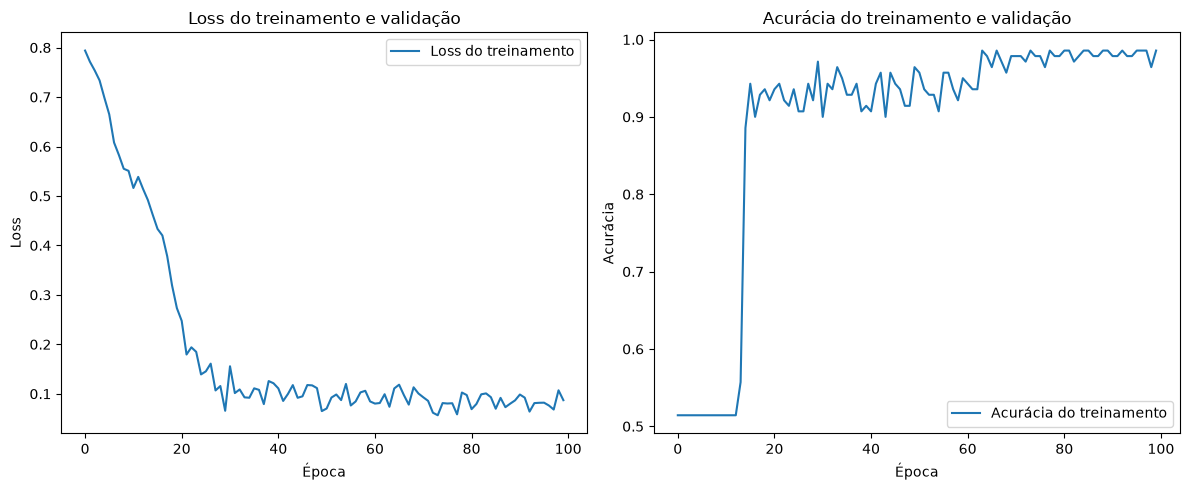

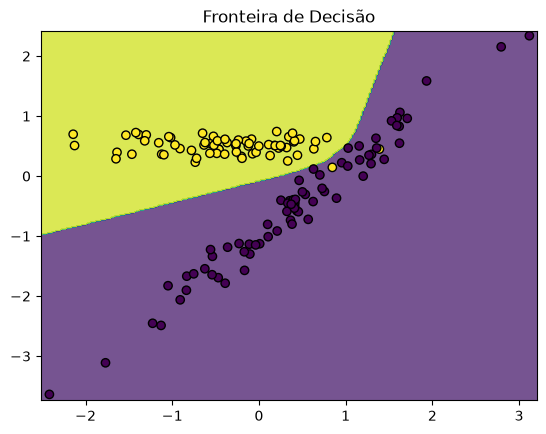

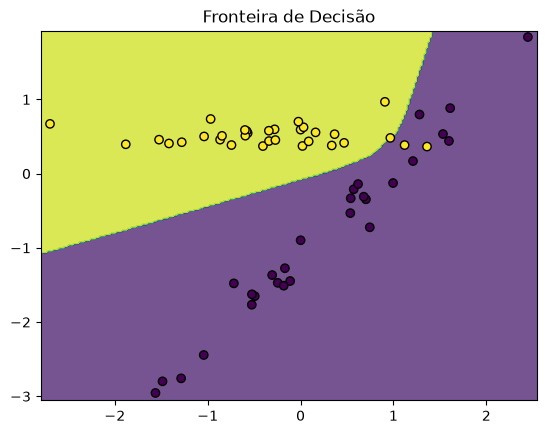

In [61]:
# Dataset de Treinamento
data = np.genfromtxt('train_dataset1.csv', delimiter=',', skip_header=1)
X_train = data[:, :-1] # Features
y_train = data[:, -1] # Labels
y_train = (y_train + 1) // 2

# Dataset de Teste
data = np.genfromtxt('test_dataset1.csv', delimiter=',', skip_header=1)
X_test = data[:, :-1] # Features
y_test = data[:, -1] # Labels
y_test = (y_test + 1) // 2

# Criar e treinar o modelo
mlp = MLPClassifier(optimizer='adam',
                    learning_rate=0.001,
                    hidden_layers=[50, 128, 64, 4],
                    activation='relu',
                    regularization='dropout',
                    dropout_p=0.1)

# Treinar o modelo
mlp.fit(X_train, y_train)

# Avaliar no conjunto de teste
test_acc = mlp.evaluate(X_test, y_test)
print(f"\nAcurácia do Teste: {test_acc*100:.2f}%")

# Plotar histórico de treinamento
mlp.plot_training_history()

# Plotar fronteira de decisão (apenas para dados 2D)
mlp.plot_decision_boundary(X_train, y_train)

mlp.predict(X_test)
mlp.plot_decision_boundary(X_test, y_test)

### Treinamento de teste da MPL usando o Dataset 2

Usando dispositivo: cpu
Cuda habilitado? False
Época 1/100 - Treinamento Loss: 0.7754, Validação acurácia: 49.71%, 
Época 10/100 - Treinamento Loss: 0.2863, Validação acurácia: 96.00%, 
Época 20/100 - Treinamento Loss: 0.0343, Validação acurácia: 99.43%, 
Época 30/100 - Treinamento Loss: 0.0402, Validação acurácia: 99.43%, 
Época 40/100 - Treinamento Loss: 0.0598, Validação acurácia: 97.71%, 
Época 50/100 - Treinamento Loss: 0.0372, Validação acurácia: 99.43%, 
Época 60/100 - Treinamento Loss: 0.0245, Validação acurácia: 100.00%, 
Época 70/100 - Treinamento Loss: 0.0371, Validação acurácia: 99.43%, 
Época 80/100 - Treinamento Loss: 0.0139, Validação acurácia: 100.00%, 
Época 90/100 - Treinamento Loss: 0.0217, Validação acurácia: 100.00%, 
Época 100/100 - Treinamento Loss: 0.0191, Validação acurácia: 99.43%, 
Tempo total de treinamento: 2.02 segundos

Acurácia do Teste: 100.00%


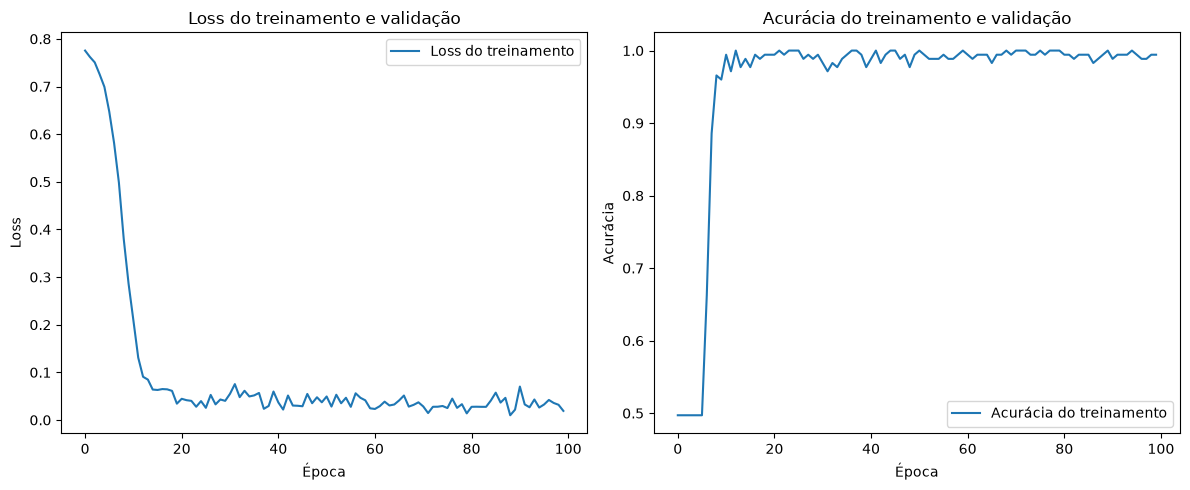

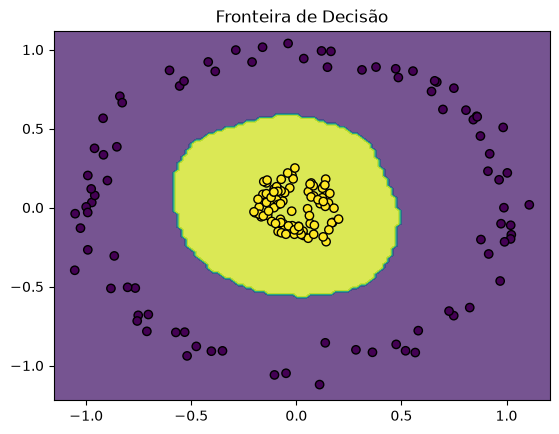

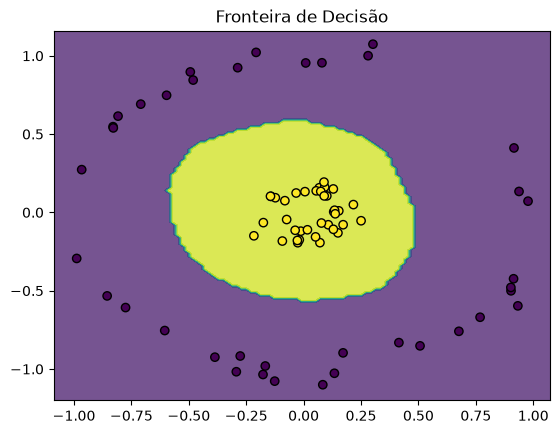

In [62]:
# Dataset de Treinamento
data = np.genfromtxt('train_dataset2.csv', delimiter=',', skip_header=1)
X_train = data[:, :-1] # Features
y_train = data[:, -1] # Labels
y_train = (y_train + 1) // 2

# Dataset de Teste
data = np.genfromtxt('test_dataset2.csv', delimiter=',', skip_header=1)
X_test = data[:, :-1] # Features
y_test = data[:, -1] # Labels
y_test = (y_test + 1) // 2

# Criar e treinar o modelo
mlp = MLPClassifier(optimizer='adam',
                    learning_rate=0.001,
                    hidden_layers=[50, 128, 64, 4],
                    activation='relu',
                    regularization='dropout',
                    dropout_p=0.1)

# Treinar o modelo
mlp.fit(X_train, y_train)

# Avaliar no conjunto de teste
test_acc = mlp.evaluate(X_test, y_test)
print(f"\nAcurácia do Teste: {test_acc*100:.2f}%")

# Plotar histórico de treinamento
mlp.plot_training_history()

# Plotar fronteira de decisão (apenas para dados 2D)
mlp.plot_decision_boundary(X_train, y_train)

mlp.predict(X_test)
mlp.plot_decision_boundary(X_test, y_test)

### Treinamento de teste da MPL usando o Dataset 3

Usando dispositivo: cpu
Cuda habilitado? False
Época 1/100 - Treinamento Loss: 0.7514, Validação acurácia: 46.94%, 
Época 10/100 - Treinamento Loss: 0.2459, Validação acurácia: 90.48%, 
Época 20/100 - Treinamento Loss: 0.1820, Validação acurácia: 89.12%, 
Época 30/100 - Treinamento Loss: 0.1733, Validação acurácia: 95.24%, 
Época 40/100 - Treinamento Loss: 0.1224, Validação acurácia: 95.92%, 
Época 50/100 - Treinamento Loss: 0.0816, Validação acurácia: 98.64%, 
Época 60/100 - Treinamento Loss: 0.0511, Validação acurácia: 98.64%, 
Época 70/100 - Treinamento Loss: 0.0539, Validação acurácia: 99.32%, 
Época 80/100 - Treinamento Loss: 0.0514, Validação acurácia: 98.64%, 
Época 90/100 - Treinamento Loss: 0.0569, Validação acurácia: 99.32%, 
Época 100/100 - Treinamento Loss: 0.0373, Validação acurácia: 100.00%, 
Tempo total de treinamento: 1.88 segundos

Acurácia do Teste: 87.30%


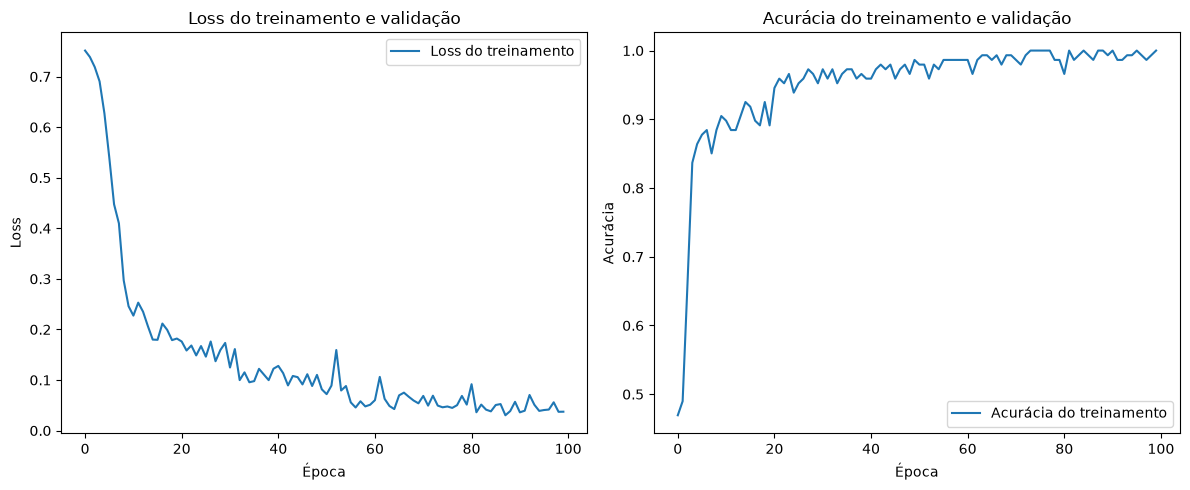

A fronteira de decisão só pode ser plotada para dados 2D
A fronteira de decisão só pode ser plotada para dados 2D


In [63]:
# Dataset de Treinamento
data = np.genfromtxt('train_dataset3.csv', delimiter=',', skip_header=1)
X_train = data[:, :-1] # Features
y_train = data[:, -1] # Labels
y_train = (y_train + 1) // 2

# Dataset de Teste
data = np.genfromtxt('test_dataset3.csv', delimiter=',', skip_header=1)
X_test = data[:, :-1] # Features
y_test = data[:, -1] # Labels
y_test = (y_test + 1) // 2

# Criar e treinar o modelo
mlp = MLPClassifier(optimizer='adam',
                    learning_rate=0.001,
                    hidden_layers=[50, 128, 64, 4],
                    activation='relu',
                    regularization='dropout',
                    dropout_p=0.1)

# Treinar o modelo
mlp.fit(X_train, y_train)

# Avaliar no conjunto de teste
test_acc = mlp.evaluate(X_test, y_test)
print(f"\nAcurácia do Teste: {test_acc*100:.2f}%")

# Plotar histórico de treinamento
mlp.plot_training_history()

# Plotar fronteira de decisão (apenas para dados 2D)
mlp.plot_decision_boundary(X_train, y_train)

mlp.predict(X_test)
mlp.plot_decision_boundary(X_test, y_test)

### Treinamento de teste da MPL usando o Dataset 4

In [74]:
### Dataset de treino
data = np.genfromtxt('train_dataset.csv', delimiter=',', skip_header=1)
X_train = data[:, :-1] # Features
y_train = data[:, -1] # Labels

### Dataset de validation
data = np.genfromtxt('validation_dataset.csv', delimiter=',', skip_header=1)
X_val = data[:, :-1] # Features
y_val = data[:, -1] # Labels

### Dataset de teste
data = np.genfromtxt('test_dataset.csv', delimiter=',', skip_header=1)
X_test = data[:, :-1] # Features
y_test = data[:, -1] # Labels

### Cenário 1

Usando dispositivo: cpu
Cuda habilitado? False
Época 1/100 - Treinamento Loss: 1.4010, Validação acurácia: 25.52%, Validação Loss: 1.4027, Validação Acurácia: 24.48%
Época 10/100 - Treinamento Loss: 1.3872, Validação acurácia: 25.52%, Validação Loss: 1.3899, Validação Acurácia: 24.48%
Época 20/100 - Treinamento Loss: 1.3766, Validação acurácia: 25.52%, Validação Loss: 1.3811, Validação Acurácia: 24.48%
Época 30/100 - Treinamento Loss: 1.3594, Validação acurácia: 25.91%, Validação Loss: 1.3683, Validação Acurácia: 25.52%
Época 40/100 - Treinamento Loss: 1.3234, Validação acurácia: 35.81%, Validação Loss: 1.3397, Validação Acurácia: 32.81%
Época 50/100 - Treinamento Loss: 1.2271, Validação acurácia: 51.43%, Validação Loss: 1.2592, Validação Acurácia: 48.44%
Época 60/100 - Treinamento Loss: 1.0362, Validação acurácia: 67.71%, Validação Loss: 1.0917, Validação Acurácia: 64.06%
Época 70/100 - Treinamento Loss: 0.8050, Validação acurácia: 78.26%, Validação Loss: 0.8932, Validação Acurácia: 7

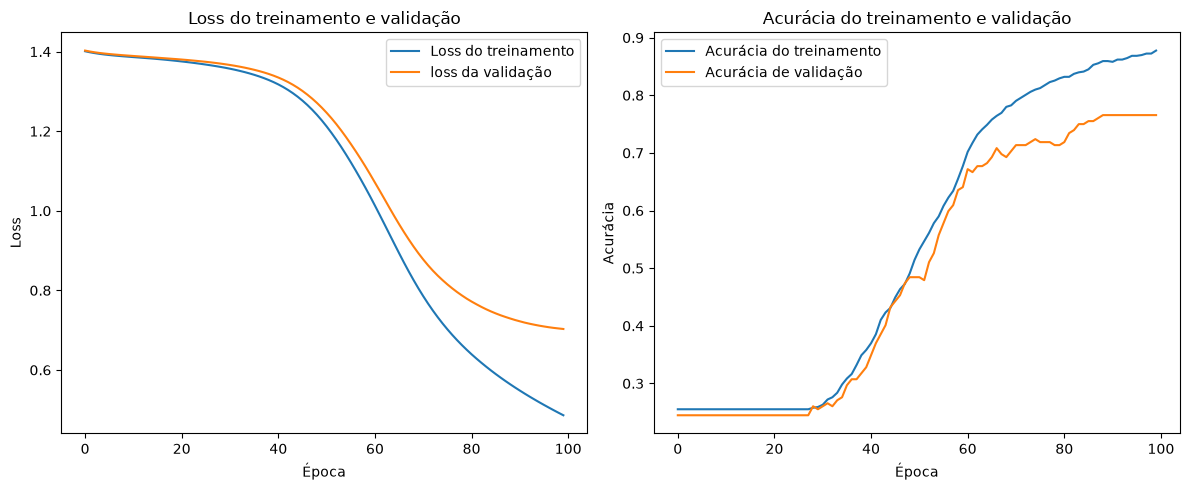

In [75]:
# Cenário 1
model = MLPClassifier(optimizer='SGD',
                      learning_rate=0.01,
                      hidden_layers=[50, 64, 4],
                      activation='relu',
                      regularization=None)

# Treinar o modelo
model.fit(X_train, y_train, X_val, y_val)

# Avaliar no conjunto de teste
test_acc = model.evaluate(X_test, y_test)
print(f"Acurácia do teste {test_acc*100:.2f}%")

# Plotar histórico de treinamento
model.plot_training_history()
